# Medium Dataset 1 - UNSW-NB15 Supervised Classification

This notebook evaluates supervised machine learning models on the UNSW-NB15 network intrusion dataset.

The goal is to distinguish normal network traffic from attack traffic using a leakage-safe preprocessing and evaluation pipeline.

In [2]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.feature_selection import mutual_info_classif

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.12.7
NumPy: 2.5.3
Pandas: 3.0.6


## Load UNSW-NB15 Training and Testing Files

In [4]:
TRAIN_PATH = Path("../data/medium/UNSW_NB15_training-set.csv")
TEST_PATH = Path("../data/medium/UNSW_NB15_testing-set.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (175341, 45)
Testing shape: (82332, 45)


### Observation

The official UNSW-NB15 training set contains 175,341 records and the testing set contains 82,332 records, with 45 columns in each file. The original train-test split will be preserved for model development and final evaluation.

## Check Dataset Structure

In [5]:
print("Training columns:", len(train_df.columns))
print("Testing columns:", len(test_df.columns))

print("\nSame columns in both datasets:")
print(train_df.columns.equals(test_df.columns))

print("\nColumn names:")
print(train_df.columns.tolist())

Training columns: 45
Testing columns: 45

Same columns in both datasets:
True

Column names:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


## Check Data Types

In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  str    
 3   service            175341 non-null  str    
 4   state              175341 non-null  str    
 5   spkts              175341 non-null  int64  
 6   dpkts              175341 non-null  int64  
 7   sbytes             175341 non-null  int64  
 8   dbytes             175341 non-null  int64  
 9   rate               175341 non-null  float64
 10  sttl               175341 non-null  int64  
 11  dttl               175341 non-null  int64  
 12  sload              175341 non-null  float64
 13  dload              175341 non-null  float64
 14  sloss              175341 non-null  int64  
 15  dloss              175341 non-null  int64  
 16  sinpkt       

## Check Categorical Features

In [7]:
categorical_columns = train_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumber of categorical columns:", len(categorical_columns))

Categorical columns:
['proto', 'service', 'state', 'attack_cat']

Number of categorical columns: 4


## Check Target Distribution

In [8]:
print("Training class counts:")
print(
    train_df["label"]
    .value_counts()
    .sort_index()
)

print("\nTraining class percentage:")
print(
    train_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nTesting class counts:")
print(
    test_df["label"]
    .value_counts()
    .sort_index()
)

print("\nTesting class percentage:")
print(
    test_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Training class counts:
label
0     56000
1    119341
Name: count, dtype: int64

Training class percentage:
label
0    31.94
1    68.06
Name: proportion, dtype: float64

Testing class counts:
label
0    37000
1    45332
Name: count, dtype: int64

Testing class percentage:
label
0    44.94
1    55.06
Name: proportion, dtype: float64


### Observation

The UNSW-NB15 training and testing sets have different class distributions. Attack traffic is the majority class in both sets, with 68.06% attacks in the training data and 55.06% attacks in the testing data.

Because the attack class is not the minority class, SMOTE is not required at this stage.

## Check Missing Values and Duplicates

In [9]:
print("Training missing values:", train_df.isna().sum().sum())
print("Testing missing values:", test_df.isna().sum().sum())

print("\nTraining duplicate rows:", train_df.duplicated().sum())
print("Testing duplicate rows:", test_df.duplicated().sum())

Training missing values: 0
Testing missing values: 0

Training duplicate rows: 0
Testing duplicate rows: 0


In [10]:
train_missing = train_df.isna().sum()
test_missing = test_df.isna().sum()

print("Training columns with missing values:")
print(train_missing[train_missing > 0])

print("\nTesting columns with missing values:")
print(test_missing[test_missing > 0])

Training columns with missing values:
Series([], dtype: int64)

Testing columns with missing values:
Series([], dtype: int64)


### Observation

No missing values or exact duplicate rows were found in either the training or testing dataset, so no imputation or duplicate removal is required.

## Inspect Identifier and Attack Category

In [11]:
print("ID sample:")
print(train_df["id"].head())

print("\nAttack categories:")
print(train_df["attack_cat"].value_counts())

ID sample:
0    1
1    2
2    3
3    4
4    5
Name: id, dtype: int64

Attack categories:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64


## Remove Leakage-Prone Columns

In [12]:
train_clean = train_df.drop(
    columns=["id", "attack_cat"]
).copy()

test_clean = test_df.drop(
    columns=["id", "attack_cat"]
).copy()

print("Training shape after removal:", train_clean.shape)
print("Testing shape after removal:", test_clean.shape)

Training shape after removal: (175341, 43)
Testing shape after removal: (82332, 43)


### Observation

The `id` column was removed because it is only a record identifier. The `attack_cat` column was removed to prevent target leakage, since it directly describes the type of attack.

## Split Features and Target

In [13]:
X_train = train_clean.drop(columns="label")
y_train = train_clean["label"].astype(int)

X_test = test_clean.drop(columns="label")
y_test = test_clean["label"].astype(int)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (175341, 42)
X_test shape: (82332, 42)
y_train shape: (175341,)
y_test shape: (82332,)


## Identify Categorical and Numerical Features

In [14]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumber of categorical features:", len(categorical_features))

print("\nNumber of numerical features:", len(numerical_features))

Categorical features:
['proto', 'service', 'state']

Number of categorical features: 3

Number of numerical features: 39


### Observation

The dataset contains 3 categorical features (`proto`, `service`, and `state`) and the remaining predictors are numerical. The categorical features require encoding before model training.

## Check Categorical Feature Cardinality

In [15]:
for column in categorical_features:
    print(
        f"{column}:",
        X_train[column].nunique(),
        "unique values"
    )

proto: 133 unique values
service: 13 unique values
state: 9 unique values


### Observation

The categorical features have 133 protocol values, 13 service values and 9 connection states. One-hot encoding is suitable because these categories have no natural ordinal relationship.

## Build Preprocessing Pipelines

Categorical features are one-hot encoded. Numerical features are standardized only for models that are sensitive to feature scale.

In [16]:
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        )
    ]
)

## Create Training and Validation Sets

A stratified validation set is created from the official training data. The official test set is kept untouched for final evaluation.

In [17]:
X_train_fit, X_val, y_train_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print("Training subset:", X_train_fit.shape)
print("Validation subset:", X_val.shape)

print("\nTraining class distribution:")
print(
    y_train_fit.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nValidation class distribution:")
print(
    y_val.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Training subset: (140272, 42)
Validation subset: (35069, 42)

Training class distribution:
label
0    31.94
1    68.06
Name: proportion, dtype: float64

Validation class distribution:
label
0    31.94
1    68.06
Name: proportion, dtype: float64


### Observation

The stratified split preserves the class distribution in both training and validation data. The official UNSW-NB15 test set remains untouched for final model evaluation.

# Baseline Supervised Models

Six individual classifiers are first evaluated using their default or reasonable baseline settings. The strongest models will later be used to construct the Voting Classifier.

In [18]:
baseline_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", scaled_preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessor", scaled_preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=5,
            n_jobs=-1
        ))
    ]),

    "Linear SVM": Pipeline([
        ("preprocessor", scaled_preprocessor),
        ("model", LinearSVC(
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "LightGBM": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ))
    ])
}

## Baseline Validation Results

In [19]:
baseline_results = []

trained_baseline_models = {}

for name, model in baseline_models.items():

    print(f"Training {name}...")

    model.fit(
        X_train_fit,
        y_train_fit
    )

    y_val_pred = model.predict(
        X_val
    )

    trained_baseline_models[name] = model

    baseline_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val,
            y_val_pred
        ),
        "Precision": precision_score(
            y_val,
            y_val_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val,
            y_val_pred,
            zero_division=0
        )
    })

baseline_results_df = pd.DataFrame(
    baseline_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

baseline_results_df.round(4)

Training Logistic Regression...
Training KNN...
Training Linear SVM...
Training Random Forest...
Training XGBoost...
Training LightGBM...


,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.9597,0.9634,0.9779,0.9706
1,LightGBM,0.9589,0.9640,0.9760,0.9700
2,XGBoost,0.9557,0.9602,0.9753,0.9677
3,KNN,0.9386,0.9486,0.9620,0.9552
4,Linear SVM,0.9365,0.9205,0.9925,0.9551
5,Logistic Regression,0.9364,0.9237,0.9883,0.9549


### Observation

Tree-based ensemble models perform best on the validation set. Random Forest achieves the highest F1-score of 0.9706, followed closely by LightGBM and XGBoost. Linear models and KNN also perform well, but remain slightly behind the ensemble methods.

## Feature Selection

Mutual Information is used to identify the most informative features. The effect of feature selection is evaluated on the strongest ensemble models.

In [20]:
X_train_encoded = tree_preprocessor.fit_transform(
    X_train_fit
)

X_val_encoded = tree_preprocessor.transform(
    X_val
)

feature_names = tree_preprocessor.get_feature_names_out()

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded validation shape:", X_val_encoded.shape)
print("Number of features:", len(feature_names))

Encoded training shape: (140272, 192)
Encoded validation shape: (35069, 192)
Number of features: 192


In [21]:
mi_scores = mutual_info_classif(
    X_train_encoded,
    y_train_fit,
    random_state=RANDOM_STATE
)

mi_df = pd.DataFrame({
    "Feature": feature_names,
    "Mutual Information": mi_scores
})

mi_df = mi_df.sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

mi_df.head(20)

,Feature,Mutual Information
0,num__sload,0.596947
1,num__dur,0.551037
2,num__rate,0.548546
3,num__dload,0.492831
4,num__sbytes,0.483972
5,num__dinpkt,0.480170
6,num__sinpkt,0.447401
7,num__sjit,0.405807
8,num__djit,0.387164
9,num__dbytes,0.380431


## Top Mutual Information Features

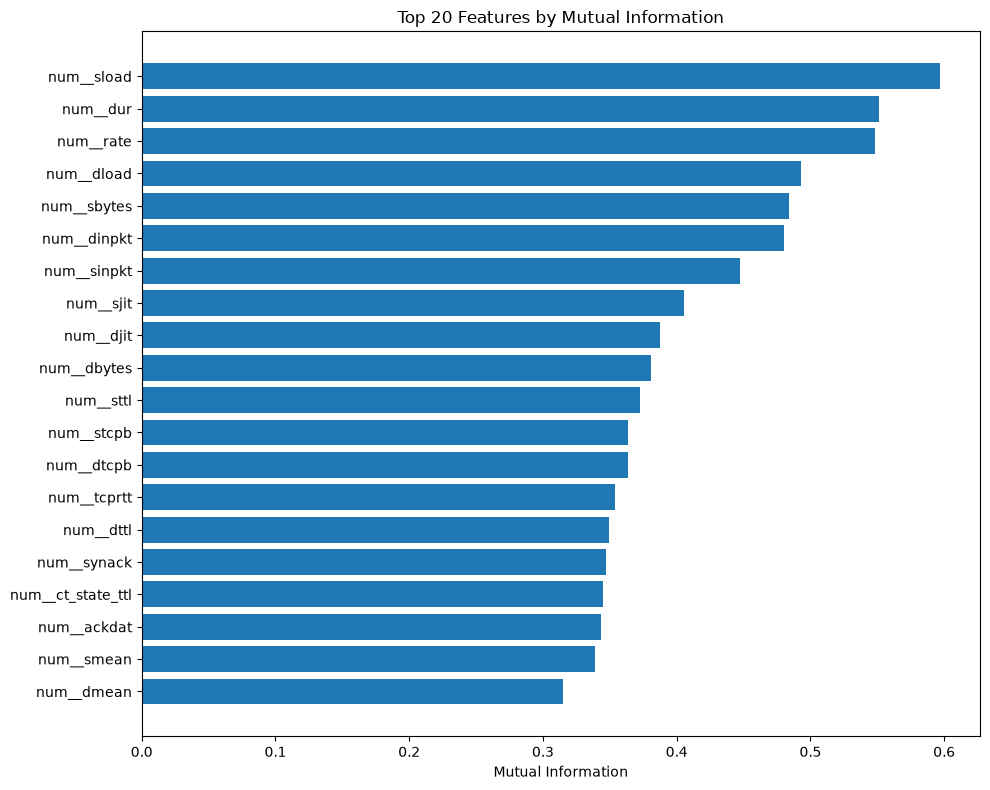

In [22]:
top_mi = mi_df.head(20)

plt.figure(figsize=(10, 8))

plt.barh(
    top_mi["Feature"],
    top_mi["Mutual Information"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mutual Information")
plt.title("Top 20 Features by Mutual Information")

plt.tight_layout()
plt.show()

### Observation

Several network traffic features show strong dependence on the target label. `sload`, `dur`, `rate`, `dload`, and `sbytes` have the highest Mutual Information scores, indicating that the UNSW-NB15 dataset contains strong predictive structure for distinguishing normal and attack traffic.

In [23]:
feature_index = {
    feature: index
    for index, feature in enumerate(feature_names)
}

feature_counts = [
    20,
    40,
    60,
    100,
    len(feature_names)
]

feature_selection_results = []

In [24]:
for k in feature_counts:

    top_features = mi_df.head(k)["Feature"].tolist()

    selected_indices = [
        feature_index[feature]
        for feature in top_features
    ]

    X_train_k = X_train_encoded[:, selected_indices]
    X_val_k = X_val_encoded[:, selected_indices]

    models_k = {
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "XGBoost": XGBClassifier(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        "LightGBM": LGBMClassifier(
            n_estimators=300,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        )
    }

    for name, model in models_k.items():

        model.fit(
            X_train_k,
            y_train_fit
        )

        y_pred = model.predict(
            X_val_k
        )

        feature_selection_results.append({
            "Model": name,
            "Number of Features": k,
            "Accuracy": accuracy_score(
                y_val,
                y_pred
            ),
            "Precision": precision_score(
                y_val,
                y_pred,
                zero_division=0
            ),
            "Recall": recall_score(
                y_val,
                y_pred,
                zero_division=0
            ),
            "F1-Score": f1_score(
                y_val,
                y_pred,
                zero_division=0
            )
        })

## Feature Selection Results

In [25]:
feature_selection_df = pd.DataFrame(
    feature_selection_results
)

feature_selection_df = (
    feature_selection_df
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_selection_df.round(4)

,Model,Number of Features,Accuracy,Precision,Recall,F1-Score
0,Random Forest,100,0.9605,0.9642,0.9783,0.9712
1,Random Forest,60,0.9602,0.9640,0.9780,0.9709
2,Random Forest,192,0.9601,0.9642,0.9777,0.9709
3,Random Forest,40,0.9592,0.9626,0.9780,0.9702
4,LightGBM,192,0.9588,0.9640,0.9758,0.9699
5,LightGBM,60,0.9584,0.9635,0.9759,0.9697
6,LightGBM,100,0.9583,0.9632,0.9760,0.9696
7,LightGBM,40,0.9582,0.9622,0.9770,0.9695
8,XGBoost,100,0.9557,0.9601,0.9755,0.9677
9,XGBoost,192,0.9557,0.9602,0.9754,0.9677


In [26]:
feature_summary = feature_selection_df.pivot(
    index="Number of Features",
    columns="Model",
    values="F1-Score"
)

feature_summary.round(4)

Model,LightGBM,Random Forest,XGBoost
Number of Features,,,
20,0.9613,0.9625,0.9605
40,0.9695,0.9702,0.9677
60,0.9697,0.9709,0.9675
100,0.9696,0.9712,0.9677
192,0.9699,0.9709,0.9677


## Effect of Feature Selection

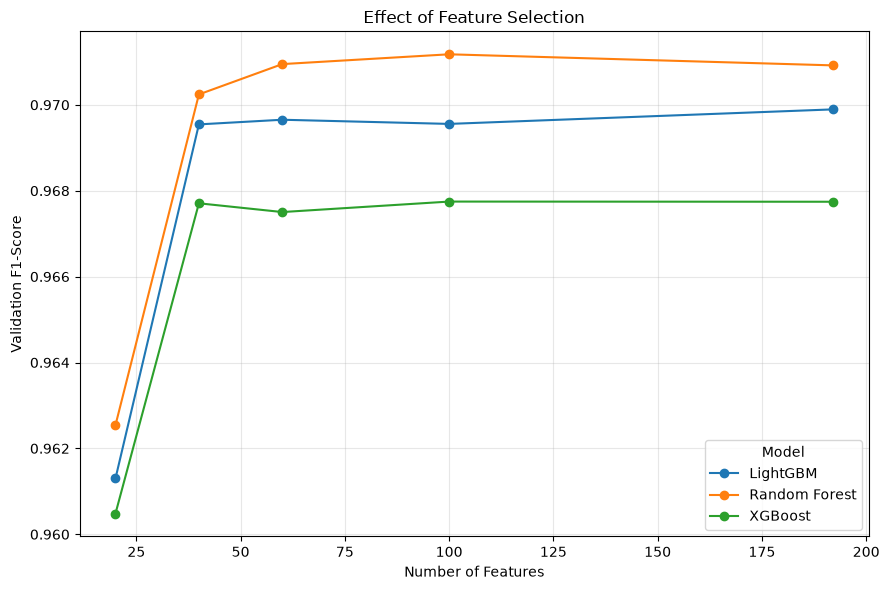

In [27]:
feature_summary.plot(
    marker="o",
    figsize=(9, 6)
)

plt.xlabel("Number of Features")
plt.ylabel("Validation F1-Score")
plt.title("Effect of Feature Selection")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Observation

Feature selection reduces the encoded feature space from 192 features while preserving almost all predictive performance. Random Forest reaches its highest validation F1-score with 100 features, while 40–60 features already achieve nearly the same performance.

A 60-feature subset is selected as a balanced choice between predictive performance and model complexity.

## Select Final Feature Subset

In [28]:
FINAL_K = 60

selected_features = mi_df.head(
    FINAL_K
)["Feature"].tolist()

selected_indices = [
    feature_index[feature]
    for feature in selected_features
]

X_train_selected = X_train_encoded[
    :,
    selected_indices
]

X_val_selected = X_val_encoded[
    :,
    selected_indices
]

print(
    "Selected feature count:",
    len(selected_features)
)

print(
    "Selected training shape:",
    X_train_selected.shape
)

Selected feature count: 60
Selected training shape: (140272, 60)


# Hyperparameter Optimization with Optuna

Optuna is used to optimize the strongest ensemble models on the selected 60-feature subset. The objective is to maximize validation F1-score.

In [30]:
import optuna

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

## Random Forest - Optuna

In [31]:
def objective_rf(trial):

    model = RandomForestClassifier(
        n_estimators=trial.suggest_int(
            "n_estimators",
            150,
            500
        ),
        max_depth=trial.suggest_int(
            "max_depth",
            10,
            40
        ),
        min_samples_split=trial.suggest_int(
            "min_samples_split",
            2,
            10
        ),
        min_samples_leaf=trial.suggest_int(
            "min_samples_leaf",
            1,
            5
        ),
        max_features=trial.suggest_categorical(
            "max_features",
            ["sqrt", "log2"]
        ),
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(
        X_train_selected,
        y_train_fit
    )

    y_pred = model.predict(
        X_val_selected
    )

    return f1_score(
        y_val,
        y_pred
    )

In [32]:
rf_study = optuna.create_study(
    direction="maximize"
)

rf_study.optimize(
    objective_rf,
    n_trials=20
)

print("Best Random Forest Parameters:")
print(rf_study.best_params)

print("\nBest Validation F1:")
print(
    round(
        rf_study.best_value,
        4
    )
)

Best Random Forest Parameters:
{'n_estimators': 419, 'max_depth': 35, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}

Best Validation F1:
0.9714


## XGBoost - Optuna

In [33]:
def objective_xgb(trial):

    model = XGBClassifier(
        n_estimators=trial.suggest_int(
            "n_estimators",
            150,
            500
        ),
        max_depth=trial.suggest_int(
            "max_depth",
            3,
            10
        ),
        learning_rate=trial.suggest_float(
            "learning_rate",
            0.01,
            0.2,
            log=True
        ),
        subsample=trial.suggest_float(
            "subsample",
            0.7,
            1.0
        ),
        colsample_bytree=trial.suggest_float(
            "colsample_bytree",
            0.7,
            1.0
        ),
        min_child_weight=trial.suggest_int(
            "min_child_weight",
            1,
            10
        ),
        gamma=trial.suggest_float(
            "gamma",
            0.0,
            2.0
        ),
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    model.fit(
        X_train_selected,
        y_train_fit
    )

    y_pred = model.predict(
        X_val_selected
    )

    return f1_score(
        y_val,
        y_pred
    )

In [34]:
xgb_study = optuna.create_study(
    direction="maximize"
)

xgb_study.optimize(
    objective_xgb,
    n_trials=20
)

print("Best XGBoost Parameters:")
print(xgb_study.best_params)

print("\nBest Validation F1:")
print(
    round(
        xgb_study.best_value,
        4
    )
)

Best XGBoost Parameters:
{'n_estimators': 414, 'max_depth': 9, 'learning_rate': 0.07245909751864098, 'subsample': 0.8258092495703482, 'colsample_bytree': 0.9326620973333799, 'min_child_weight': 2, 'gamma': 0.2124264320135802}

Best Validation F1:
0.9721


## LightGBM - Optuna

In [35]:
def objective_lgbm(trial):

    model = LGBMClassifier(
        n_estimators=trial.suggest_int(
            "n_estimators",
            150,
            500
        ),
        learning_rate=trial.suggest_float(
            "learning_rate",
            0.01,
            0.2,
            log=True
        ),
        num_leaves=trial.suggest_int(
            "num_leaves",
            20,
            100
        ),
        max_depth=trial.suggest_int(
            "max_depth",
            5,
            25
        ),
        min_child_samples=trial.suggest_int(
            "min_child_samples",
            10,
            50
        ),
        subsample=trial.suggest_float(
            "subsample",
            0.7,
            1.0
        ),
        colsample_bytree=trial.suggest_float(
            "colsample_bytree",
            0.7,
            1.0
        ),
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(
        X_train_selected,
        y_train_fit
    )

    y_pred = model.predict(
        X_val_selected
    )

    return f1_score(
        y_val,
        y_pred
    )

In [36]:
lgbm_study = optuna.create_study(
    direction="maximize"
)

lgbm_study.optimize(
    objective_lgbm,
    n_trials=20
)

print("Best LightGBM Parameters:")
print(lgbm_study.best_params)

print("\nBest Validation F1:")
print(
    round(
        lgbm_study.best_value,
        4
    )
)

Best LightGBM Parameters:
{'n_estimators': 327, 'learning_rate': 0.10288308857473874, 'num_leaves': 74, 'max_depth': 18, 'min_child_samples': 15, 'subsample': 0.883269411205806, 'colsample_bytree': 0.9330955954296156}

Best Validation F1:
0.9733


## Optuna Tuning Results

In [38]:
optuna_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "Best Validation F1": [
        rf_study.best_value,
        xgb_study.best_value,
        lgbm_study.best_value
    ]
})

optuna_results = (
    optuna_results
    .sort_values(
        "Best Validation F1",
        ascending=False
    )
    .reset_index(drop=True)
)

optuna_results.round(4)

,Model,Best Validation F1
0,LightGBM,0.9733
1,XGBoost,0.9721
2,Random Forest,0.9714


## Evaluate Optimized Models

In [39]:
best_rf = RandomForestClassifier(
    **rf_study.best_params,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

best_xgb = XGBClassifier(
    **xgb_study.best_params,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

best_lgbm = LGBMClassifier(
    **lgbm_study.best_params,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

optimized_models = {
    "Random Forest": best_rf,
    "XGBoost": best_xgb,
    "LightGBM": best_lgbm
}

In [40]:
optimized_results = []

for name, model in optimized_models.items():

    model.fit(
        X_train_selected,
        y_train_fit
    )

    y_pred = model.predict(
        X_val_selected
    )

    optimized_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val,
            y_pred
        ),
        "Precision": precision_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_pred,
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_val,
            y_pred,
            zero_division=0
        )
    })

optimized_results_df = pd.DataFrame(
    optimized_results
).sort_values(
    "F1-Score",
    ascending=False
).reset_index(drop=True)

optimized_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,LightGBM,0.9634,0.9681,0.9785,0.9733
1,XGBoost,0.9618,0.9667,0.9775,0.9721
2,Random Forest,0.9607,0.9623,0.9807,0.9714


## Voting Classifier

A soft-voting ensemble combines the predictions of the optimized Random Forest, XGBoost and LightGBM models.

In [41]:
voting_model = VotingClassifier(
    estimators=[
        ("rf", best_rf),
        ("xgb", best_xgb),
        ("lgbm", best_lgbm)
    ],
    voting="soft",
    n_jobs=-1
)

voting_model.fit(
    X_train_selected,
    y_train_fit
)

voting_pred = voting_model.predict(
    X_val_selected
)

voting_result = {
    "Model": "Voting Classifier",
    "Accuracy": accuracy_score(
        y_val,
        voting_pred
    ),
    "Precision": precision_score(
        y_val,
        voting_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_val,
        voting_pred,
        zero_division=0
    ),
    "F1-Score": f1_score(
        y_val,
        voting_pred,
        zero_division=0
    )
}

pd.DataFrame([voting_result]).round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Voting Classifier,0.9631,0.9668,0.9795,0.9731


## Final Validation Comparison

In [42]:
final_validation_results = pd.concat(
    [
        optimized_results_df,
        pd.DataFrame([voting_result])
    ],
    ignore_index=True
)

final_validation_results = (
    final_validation_results
    .sort_values(
        "F1-Score",
        ascending=False
    )
    .reset_index(drop=True)
)

final_validation_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,LightGBM,0.9634,0.9681,0.9785,0.9733
1,Voting Classifier,0.9631,0.9668,0.9795,0.9731
2,XGBoost,0.9618,0.9667,0.9775,0.9721
3,Random Forest,0.9607,0.9623,0.9807,0.9714


### Observation

LightGBM achieves the best validation performance with an F1-score of 0.9733 and Accuracy of 0.9634. The Voting Classifier performs almost identically, but LightGBM is selected as the final model because it provides the highest F1-score with lower model complexity.

# Final Model Training

In [43]:
# transform the complete official training and testing sets
X_train_full_encoded = tree_preprocessor.fit_transform(
    X_train
)

X_test_full_encoded = tree_preprocessor.transform(
    X_test
)

full_feature_names = tree_preprocessor.get_feature_names_out()

print("Full training shape:", X_train_full_encoded.shape)
print("Official test shape:", X_test_full_encoded.shape)

Full training shape: (175341, 194)
Official test shape: (82332, 194)


## Select Final 60 Features

In [44]:
full_mi_scores = mutual_info_classif(
    X_train_full_encoded,
    y_train,
    random_state=RANDOM_STATE
)

full_mi_df = pd.DataFrame({
    "Feature": full_feature_names,
    "Mutual Information": full_mi_scores
})

full_mi_df = full_mi_df.sort_values(
    "Mutual Information",
    ascending=False
).reset_index(drop=True)

final_selected_features = full_mi_df.head(
    FINAL_K
)["Feature"].tolist()

full_feature_index = {
    feature: index
    for index, feature in enumerate(full_feature_names)
}

final_selected_indices = [
    full_feature_index[feature]
    for feature in final_selected_features
]

X_train_final = X_train_full_encoded[
    :,
    final_selected_indices
]

X_test_final = X_test_full_encoded[
    :,
    final_selected_indices
]

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (175341, 60)
Final testing shape: (82332, 60)


## Train Final LightGBM Model

In [45]:
final_lgbm = LGBMClassifier(
    **lgbm_study.best_params,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

final_lgbm.fit(
    X_train_final,
    y_train
)

,num_leaves,74
,max_depth,18
,learning_rate,0.10288308857473874
,n_estimators,327
,min_child_samples,15
,subsample,0.883269411205806
,colsample_bytree,0.9330955954296156
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'


## Final Official Test Evaluation

In [46]:
y_test_pred = final_lgbm.predict(
    X_test_final
)

final_test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

final_test_precision = precision_score(
    y_test,
    y_test_pred,
    zero_division=0
)

final_test_recall = recall_score(
    y_test,
    y_test_pred,
    zero_division=0
)

final_test_f1 = f1_score(
    y_test,
    y_test_pred,
    zero_division=0
)

print("Model: LightGBM")
print("Accuracy:", round(final_test_accuracy, 4))
print("Precision:", round(final_test_precision, 4))
print("Recall:", round(final_test_recall, 4))
print("F1-Score:", round(final_test_f1, 4))

Model: LightGBM
Accuracy: 0.8696
Precision: 0.8196
Recall: 0.9787
F1-Score: 0.8921


## Classification Report

In [47]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "Normal",
            "Attack"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

      Normal     0.9657    0.7361    0.8354     37000
      Attack     0.8196    0.9787    0.8921     45332

    accuracy                         0.8696     82332
   macro avg     0.8927    0.8574    0.8638     82332
weighted avg     0.8853    0.8696    0.8666     82332



## Confusion Matrix

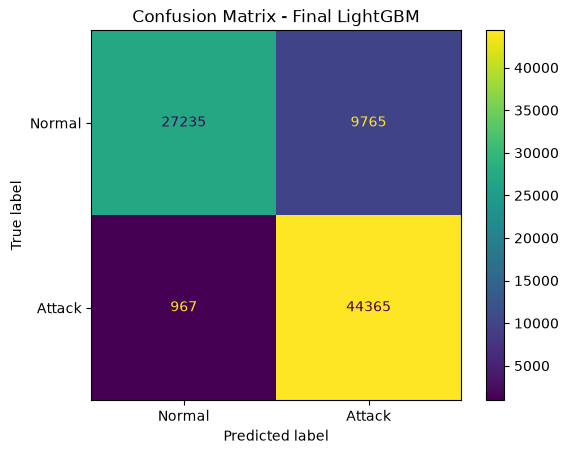

In [48]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Attack"
    ]
)

disp.plot()

plt.title(
    "Confusion Matrix - Final LightGBM"
)

plt.show()

### Observation

The final LightGBM model achieved an F1-score of 0.8921 on the official UNSW-NB15 test set, with Recall of 0.9787. The very high Recall indicates that most attack samples are detected, while the lower Precision of 0.8196 shows that some normal traffic is incorrectly classified as attack.

## Final Result Summary

In [49]:
final_result = pd.DataFrame([{
    "Model": "LightGBM",
    "Accuracy": final_test_accuracy,
    "Precision": final_test_precision,
    "Recall": final_test_recall,
    "F1-Score": final_test_f1
}])

final_result.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,LightGBM,0.8696,0.8196,0.9787,0.8921


## Save Final Results

In [50]:
RESULTS_PATH = Path("../results")
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

final_result.round(4).to_csv(
    RESULTS_PATH / "medium_unsw_final_results.csv",
    index=False
)

optuna_results.round(4).to_csv(
    RESULTS_PATH / "medium_unsw_optuna_results.csv",
    index=False
)

feature_selection_df.round(4).to_csv(
    RESULTS_PATH / "medium_unsw_feature_selection.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


# Conclusion

The UNSW-NB15 dataset was evaluated using multiple supervised machine learning models.

Tree-based ensemble methods consistently outperformed linear and distance-based models. Mutual Information feature selection reduced the encoded feature space while preserving strong predictive performance.

Optuna hyperparameter optimization further improved the ensemble models, with LightGBM achieving the best validation F1-score.

After retraining on the complete official training set, the final LightGBM model achieved an official test F1-score of 0.8921 with Recall of 0.9787.

These results show that supervised ensemble methods are highly effective when labelled network attack data is available.